In [3]:
import pandas as pd
import numpy as np
import statsmodels.api as sm

In [4]:
spy = pd.read_csv("spy_clean.csv", parse_dates=["date"])
voo = pd.read_csv("voo_clean.csv", parse_dates=["date"])
rsp = pd.read_csv("rsp_clean.csv", parse_dates=["date"])
vix = pd.read_csv("vix_clean.csv", parse_dates=["date"])
y10 = pd.read_csv("dgs10_clean.csv", parse_dates=["date"])
asvi4 = pd.read_csv("AIStocks_ASVI4_Monthly.csv", parse_dates=["date"])
asvi8 = pd.read_csv("AIStocks_ASVI8_Monthly.csv", parse_dates=["date"])
mag7 = pd.read_csv("mag7_clean.csv", parse_dates=["date"])

In [5]:
spy.shape, voo.shape, rsp.shape, vix.shape, y10.shape, asvi4.shape, asvi8.shape, mag7.shape

((121, 2),
 (121, 2),
 (121, 2),
 (121, 2),
 (121, 2),
 (121, 2),
 (121, 2),
 (121, 2))

In [6]:
df = spy.merge(rsp, on="date", how="inner", suffixes=("_spy", "_rsp"))
df = df.merge(voo, on="date", how="inner")
df = df.merge(vix,  on="date", how="inner")
df = df.merge(y10,  on="date", how="inner")
df = df.merge(asvi4, on="date", how="inner")
df = df.merge(asvi8, on="date", how="inner")
df = df.merge(mag7, on="date", how="inner")

In [7]:
df.head(10)

,date,flow_spy,flow_rsp,flow_voo,dlog_vix,dy10,ASVI4,ASVI8,mag7_ret
0,2015-12-31,0.024138,0.000684,0.041933,0.121290,0.06,0.0,0.0,0.003407
1,2016-01-31,0.009106,-0.059913,0.044331,0.103712,-0.33,0.0,0.0,-0.074812
2,2016-02-29,-0.020284,-0.044370,0.000162,0.017178,-0.20,0.0,0.0,-0.023795
3,2016-03-31,0.012057,0.013637,0.014497,-0.387381,0.04,0.0,0.0,0.101130
4,2016-04-30,0.001231,0.026139,0.017441,0.118181,0.05,0.0,0.0,-0.021196
5,2016-05-31,-0.024759,-0.000433,0.004071,-0.101123,0.01,0.0,0.0,0.070772
6,2016-06-30,-0.031152,0.017661,0.023840,0.096655,-0.35,0.0,0.0,-0.033445
7,2016-07-31,0.075914,-0.002182,0.023042,-0.275178,-0.03,0.0,0.0,0.105871
8,2016-08-31,0.003991,0.010503,0.035001,0.122732,0.12,0.0,0.0,0.006255
9,2016-09-30,-0.014081,-0.002830,0.007603,-0.009734,0.02,0.0,0.0,0.036834


In [8]:
df.shape

(121, 9)

In [9]:
df["ASVI4_lag"] = df["ASVI4"].shift(1)
df["ASVI8_lag"] = df["ASVI8"].shift(1)
df["flow_spy_lag"] = df["flow_spy"].shift(1)
df["flow_voo_lag"] = df["flow_voo"].shift(1)
df["flow_rsp_lag"] = df["flow_rsp"].shift(1)
df["mag7_ret_lag"] = df["mag7_ret"].shift(1)

In [10]:
df = df.dropna()

In [11]:
df.shape

(120, 15)

In [12]:
#SPY as dependent variable
#2016-2025

Y = df["flow_spy"]

X = df[["ASVI4_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.090
Model:                            OLS   Adj. R-squared:                  0.066
Method:                 Least Squares   F-statistic:                     2.742
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0464
Time:                        19:01:45   Log-Likelihood:                 270.16
No. Observations:                 120   AIC:                            -532.3
Df Residuals:                     116   BIC:                            -521.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.002      0.389      0.6

In [13]:
df_2020 = df[df["date"] >= "2020-01-31"].copy()
df_2021 = df[df["date"] >= "2021-01-31"].copy()
df_2022 = df[df["date"] >= "2022-01-31"].copy()
df_2023 = df[df["date"] >= "2023-01-31"].copy()
df_2024 = df[df["date"] >= "2024-01-31"].copy()

In [14]:
#2020 Flow OLS

Y = df_2020["flow_spy"]
X = sm.add_constant(df_2020[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     2.961
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0383
Time:                        19:01:45   Log-Likelihood:                 171.60
No. Observations:                  72   AIC:                            -335.2
Df Residuals:                      68   BIC:                            -326.1
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0019      0.003      0.608      0.5

In [15]:
#2021 Flow OLS

Y = df_2021["flow_spy"]
X = sm.add_constant(df_2021[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     2.183
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.100
Time:                        19:01:45   Log-Likelihood:                 144.31
No. Observations:                  60   AIC:                            -280.6
Df Residuals:                      56   BIC:                            -272.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0037      0.004      1.031      0.3

In [16]:
#2022 Flow OLS

Y = df_2022["flow_spy"]
X = sm.add_constant(df_2022[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.050
Method:                 Least Squares   F-statistic:                     1.559
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.213
Time:                        19:01:46   Log-Likelihood:                 113.85
No. Observations:                  48   AIC:                            -219.7
Df Residuals:                      44   BIC:                            -212.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0036      0.005      0.784      0.4

In [17]:
#2023 Flow OLS

Y = df_2023["flow_spy"]
X = sm.add_constant(df_2023[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.204
Model:                            OLS   Adj. R-squared:                  0.129
Method:                 Least Squares   F-statistic:                     1.642
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.199
Time:                        19:01:46   Log-Likelihood:                 86.071
No. Observations:                  36   AIC:                            -164.1
Df Residuals:                      32   BIC:                            -157.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0059      0.005      1.164      0.2

In [18]:
#RSP as dependent variable
#2016-2025

Y = df["flow_rsp"]

X = df[["ASVI4_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     1.542
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.207
Time:                        19:01:46   Log-Likelihood:                 238.55
No. Observations:                 120   AIC:                            -469.1
Df Residuals:                     116   BIC:                            -457.9
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0090      0.003      2.981      0.0

In [19]:
#2020 RSP Flow OLS

Y = df_2020["flow_rsp"]
X = sm.add_constant(df_2020[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                 -0.006
Method:                 Least Squares   F-statistic:                    0.6461
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.588
Time:                        19:01:46   Log-Likelihood:                 130.23
No. Observations:                  72   AIC:                            -252.5
Df Residuals:                      68   BIC:                            -243.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0139      0.005      2.882      0.0

In [20]:
#2021 RSP Flow OLS

Y = df_2021["flow_rsp"]
X = sm.add_constant(df_2021[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.043
Model:                            OLS   Adj. R-squared:                 -0.009
Method:                 Least Squares   F-statistic:                    0.6824
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.566
Time:                        19:01:46   Log-Likelihood:                 116.85
No. Observations:                  60   AIC:                            -225.7
Df Residuals:                      56   BIC:                            -217.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0160      0.005      3.383      0.0

In [21]:
#2022 RSP Flow OLS

Y = df_2022["flow_rsp"]
X = sm.add_constant(df_2022[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                 -0.051
Method:                 Least Squares   F-statistic:                    0.3227
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.809
Time:                        19:01:46   Log-Likelihood:                 94.114
No. Observations:                  48   AIC:                            -180.2
Df Residuals:                      44   BIC:                            -172.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0151      0.006      2.717      0.0

In [22]:
#2023 RSP Flow OLS

Y = df_2023["flow_rsp"]
X = sm.add_constant(df_2023[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.079
Method:                 Least Squares   F-statistic:                    0.1181
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.949
Time:                        19:01:46   Log-Likelihood:                 66.993
No. Observations:                  36   AIC:                            -126.0
Df Residuals:                      32   BIC:                            -119.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0148      0.007      2.011      0.0

In [23]:
#Mag7 Returns SPY OLS 2016-2025

Y = df["mag7_ret"]

X = df[["flow_spy_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model2 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.267
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     13.14
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.91e-07
Time:                        19:01:46   Log-Likelihood:                 161.40
No. Observations:                 120   AIC:                            -314.8
Df Residuals:                     116   BIC:                            -303.6
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0234      0.006      3.901   

In [24]:
#2020 Mag7 Ret SPY OLS

Y = df_2020["mag7_ret"]
X = sm.add_constant(df_2020[["flow_spy_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.298
Model:                            OLS   Adj. R-squared:                  0.267
Method:                 Least Squares   F-statistic:                     10.42
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           9.97e-06
Time:                        19:01:46   Log-Likelihood:                 90.252
No. Observations:                  72   AIC:                            -172.5
Df Residuals:                      68   BIC:                            -163.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0273      0.009      3.184   

In [25]:
#2021 Mag7 Ret SPY OLS

Y = df_2021["mag7_ret"]
X = sm.add_constant(df_2021[["flow_spy_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.325
Model:                            OLS   Adj. R-squared:                  0.289
Method:                 Least Squares   F-statistic:                     8.234
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           0.000125
Time:                        19:01:46   Log-Likelihood:                 79.824
No. Observations:                  60   AIC:                            -151.6
Df Residuals:                      56   BIC:                            -143.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0218      0.009      2.422   

In [26]:
#2022 Mag7 Ret SPY OLS

Y = df_2022["mag7_ret"]
X = sm.add_constant(df_2022[["flow_spy_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.339
Method:                 Least Squares   F-statistic:                     8.788
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           0.000111
Time:                        19:01:46   Log-Likelihood:                 63.150
No. Observations:                  48   AIC:                            -118.3
Df Residuals:                      44   BIC:                            -110.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0172      0.010      1.682   

In [27]:
#2023 Mag7 Ret SPY OLS

Y = df_2023["mag7_ret"]
X = sm.add_constant(df_2023[["flow_spy_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.205
Method:                 Least Squares   F-statistic:                     3.499
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0266
Time:                        19:01:46   Log-Likelihood:                 54.499
No. Observations:                  36   AIC:                            -101.0
Df Residuals:                      32   BIC:                            -94.66
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0359      0.010      3.478   

In [28]:
#Mag7 Returns RSP OLS 2016-2025

Y = df["mag7_ret"]

X = df[["flow_rsp_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model2 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.258
Model:                            OLS   Adj. R-squared:                  0.238
Method:                 Least Squares   F-statistic:                     12.03
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           6.49e-07
Time:                        19:01:46   Log-Likelihood:                 160.65
No. Observations:                 120   AIC:                            -313.3
Df Residuals:                     116   BIC:                            -302.1
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0237      0.007      3.601   

In [29]:
#2020 Mag7 Ret RSP OLS

Y = df_2020["mag7_ret"]
X = sm.add_constant(df_2020[["flow_rsp_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.298
Model:                            OLS   Adj. R-squared:                  0.267
Method:                 Least Squares   F-statistic:                     10.29
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.14e-05
Time:                        19:01:46   Log-Likelihood:                 90.268
No. Observations:                  72   AIC:                            -172.5
Df Residuals:                      68   BIC:                            -163.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0289      0.010      3.035   

In [30]:
#2021 Mag7 Ret RSP OLS

Y = df_2021["mag7_ret"]
X = sm.add_constant(df_2021[["flow_rsp_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.325
Model:                            OLS   Adj. R-squared:                  0.289
Method:                 Least Squares   F-statistic:                     8.342
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           0.000112
Time:                        19:01:46   Log-Likelihood:                 79.804
No. Observations:                  60   AIC:                            -151.6
Df Residuals:                      56   BIC:                            -143.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0197      0.010      1.915   

In [31]:
#2022 Mag7 Ret RSP OLS

Y = df_2022["mag7_ret"]
X = sm.add_constant(df_2022[["flow_rsp_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.379
Model:                            OLS   Adj. R-squared:                  0.336
Method:                 Least Squares   F-statistic:                     8.794
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           0.000111
Time:                        19:01:46   Log-Likelihood:                 63.037
No. Observations:                  48   AIC:                            -118.1
Df Residuals:                      44   BIC:                            -110.6
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0170      0.011      1.511   

In [32]:
#2023 Mag7 Ret RSP OLS

Y = df_2023["mag7_ret"]
X = sm.add_constant(df_2023[["flow_rsp_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     3.973
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0163
Time:                        19:01:46   Log-Likelihood:                 53.807
No. Observations:                  36   AIC:                            -99.61
Df Residuals:                      32   BIC:                            -93.28
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0366      0.012      3.162   

In [33]:
#ASVI lagged Mag7_ret OLS 2016-2025

Y = df["ASVI4"]

X = df[["mag7_ret_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model2 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI4   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.038
Method:                 Least Squares   F-statistic:                     1.954
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.125
Time:                        19:01:46   Log-Likelihood:                -77.019
No. Observations:                 120   AIC:                             162.0
Df Residuals:                     116   BIC:                             173.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0667      0.046      1.452   

In [34]:
#2020 ASVI lagged Mag7_ret OLS

Y = df_2020["ASVI4"]
X = sm.add_constant(df_2020[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI4   R-squared:                       0.102
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     3.162
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0301
Time:                        19:01:46   Log-Likelihood:                -54.747
No. Observations:                  72   AIC:                             117.5
Df Residuals:                      68   BIC:                             126.6
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0965      0.069      1.409   

In [35]:
#2021 ASVI lagged Mag7_ret OLS

Y = df_2021["ASVI4"]
X = sm.add_constant(df_2021[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI4   R-squared:                       0.110
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     2.107
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.110
Time:                        19:01:46   Log-Likelihood:                -47.928
No. Observations:                  60   AIC:                             103.9
Df Residuals:                      56   BIC:                             112.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1022      0.082      1.241   

In [36]:
#2022 ASVI lagged Mag7_ret OLS

Y = df_2022["ASVI4"]
X = sm.add_constant(df_2022[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI4   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     4.858
Date:                Wed, 11 Mar 2026   Prob (F-statistic):            0.00526
Time:                        19:01:46   Log-Likelihood:                -35.946
No. Observations:                  48   AIC:                             79.89
Df Residuals:                      44   BIC:                             87.38
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1631      0.089      1.836   

In [37]:
#2023 ASVI lagged Mag7_ret OLS

Y = df_2023["ASVI4"]
X = sm.add_constant(df_2023[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI4   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     2.244
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.102
Time:                        19:01:46   Log-Likelihood:                -30.484
No. Observations:                  36   AIC:                             68.97
Df Residuals:                      32   BIC:                             75.30
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1610      0.160      1.004   

In [38]:
#VOO as dependent variable
#2016-2025

Y = df["flow_voo"]

X = df[["ASVI4_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.012
Method:                 Least Squares   F-statistic:                    0.6951
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.557
Time:                        19:01:46   Log-Likelihood:                 325.59
No. Observations:                 120   AIC:                            -643.2
Df Residuals:                     116   BIC:                            -632.0
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0139      0.002      9.059      0.0

In [39]:
#2020 VOO Flow OLS

Y = df_2020["flow_voo"]
X = sm.add_constant(df_2020[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                 -0.012
Method:                 Least Squares   F-statistic:                    0.8772
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.457
Time:                        19:01:46   Log-Likelihood:                 191.39
No. Observations:                  72   AIC:                            -374.8
Df Residuals:                      68   BIC:                            -365.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0144      0.002      6.804      0.0

In [40]:
#2021 VOO Flow OLS

Y = df_2021["flow_voo"]
X = sm.add_constant(df_2021[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                 -0.037
Method:                 Least Squares   F-statistic:                    0.1701
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.916
Time:                        19:01:46   Log-Likelihood:                 169.07
No. Observations:                  60   AIC:                            -330.1
Df Residuals:                      56   BIC:                            -321.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0148      0.002      7.292      0.0

In [41]:
#2022 VOO Flow OLS

Y = df_2022["flow_voo"]
X = sm.add_constant(df_2022[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                 -0.037
Method:                 Least Squares   F-statistic:                    0.4793
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.698
Time:                        19:01:46   Log-Likelihood:                 137.38
No. Observations:                  48   AIC:                            -266.8
Df Residuals:                      44   BIC:                            -259.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0147      0.003      5.552      0.0

In [42]:
#2023 VOO Flow OLS

Y = df_2023["flow_voo"]
X = sm.add_constant(df_2023[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                 -0.013
Method:                 Least Squares   F-statistic:                     1.183
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.332
Time:                        19:01:46   Log-Likelihood:                 112.03
No. Observations:                  36   AIC:                            -216.1
Df Residuals:                      32   BIC:                            -209.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0163      0.003      6.394      0.0

In [43]:
#Mag7 Returns VOO OLS 2016-2025

Y = df["mag7_ret"]

X = df[["flow_voo_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model2 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.258
Model:                            OLS   Adj. R-squared:                  0.239
Method:                 Least Squares   F-statistic:                     12.17
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           5.56e-07
Time:                        19:01:46   Log-Likelihood:                 160.68
No. Observations:                 120   AIC:                            -313.4
Df Residuals:                     116   BIC:                            -302.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0249      0.009      2.831   

In [44]:
#2020 Mag7 Ret VOO OLS

Y = df_2020["mag7_ret"]
X = sm.add_constant(df_2020[["flow_voo_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.295
Model:                            OLS   Adj. R-squared:                  0.264
Method:                 Least Squares   F-statistic:                     10.28
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.15e-05
Time:                        19:01:46   Log-Likelihood:                 90.135
No. Observations:                  72   AIC:                            -172.3
Df Residuals:                      68   BIC:                            -163.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0260      0.013      2.066   

In [45]:
#2021 Mag7 Ret VOO OLS

Y = df_2021["mag7_ret"]
X = sm.add_constant(df_2021[["flow_voo_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.328
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     8.152
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           0.000136
Time:                        19:01:46   Log-Likelihood:                 79.924
No. Observations:                  60   AIC:                            -151.8
Df Residuals:                      56   BIC:                            -143.5
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0167      0.014      1.212   

In [46]:
#2022 Mag7 Ret VOO OLS

Y = df_2022["mag7_ret"]
X = sm.add_constant(df_2022[["flow_voo_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.352
Method:                 Least Squares   F-statistic:                     11.11
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.49e-05
Time:                        19:01:46   Log-Likelihood:                 63.626
No. Observations:                  48   AIC:                            -119.3
Df Residuals:                      44   BIC:                            -111.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0072      0.016      0.436   

In [47]:
#2023 Mag7 Ret VOO OLS

Y = df_2023["mag7_ret"]
X = sm.add_constant(df_2023[["flow_voo_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.195
Method:                 Least Squares   F-statistic:                     3.467
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0275
Time:                        19:01:46   Log-Likelihood:                 54.282
No. Observations:                  36   AIC:                            -100.6
Df Residuals:                      32   BIC:                            -94.23
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0475      0.018      2.696   

In [48]:
#Mag7 Ret affected by ASVI?

Y = df["mag7_ret"]
X = sm.add_constant(df[["ASVI4_lag", "dlog_vix", "dy10"]])

model = sm.OLS(Y, X).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.270
Model:                            OLS   Adj. R-squared:                  0.251
Method:                 Least Squares   F-statistic:                     13.19
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.81e-07
Time:                        19:01:46   Log-Likelihood:                 161.66
No. Observations:                 120   AIC:                            -315.3
Df Residuals:                     116   BIC:                            -304.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0217      0.006      3.576      0.0

In [49]:
#2020 Mag7 Ret ASVI OLS

Y = df_2020["mag7_ret"]
X = sm.add_constant(df_2020[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.273
Method:                 Least Squares   F-statistic:                     11.12
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           5.03e-06
Time:                        19:01:46   Log-Likelihood:                 90.549
No. Observations:                  72   AIC:                            -173.1
Df Residuals:                      68   BIC:                            -164.0
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0253      0.009      2.930      0.0

In [50]:
#2021 Mag7 Ret ASVI OLS

Y = df_2021["mag7_ret"]
X = sm.add_constant(df_2021[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.340
Model:                            OLS   Adj. R-squared:                  0.304
Method:                 Least Squares   F-statistic:                     9.257
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           4.56e-05
Time:                        19:01:46   Log-Likelihood:                 80.469
No. Observations:                  60   AIC:                            -152.9
Df Residuals:                      56   BIC:                            -144.6
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0187      0.009      2.125      0.0

In [51]:
#2022 Mag7 Ret ASVI OLS

Y = df_2022["mag7_ret"]
X = sm.add_constant(df_2022[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.413
Model:                            OLS   Adj. R-squared:                  0.373
Method:                 Least Squares   F-statistic:                     11.06
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.54e-05
Time:                        19:01:46   Log-Likelihood:                 64.405
No. Observations:                  48   AIC:                            -120.8
Df Residuals:                      44   BIC:                            -113.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0113      0.010      1.154      0.2

In [52]:
#2023 Mag7 Ret ASVI OLS

Y = df_2023["mag7_ret"]
X = sm.add_constant(df_2023[["ASVI4_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.261
Model:                            OLS   Adj. R-squared:                  0.192
Method:                 Least Squares   F-statistic:                     4.036
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0153
Time:                        19:01:46   Log-Likelihood:                 54.223
No. Observations:                  36   AIC:                            -100.4
Df Residuals:                      32   BIC:                            -94.11
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0309      0.010      3.127      0.0

In [53]:
#SPY as dependent variable
#2016-2025

Y = df["flow_spy"]

X = df[["ASVI8_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.071
Method:                 Least Squares   F-statistic:                     2.856
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0402
Time:                        19:01:46   Log-Likelihood:                 270.50
No. Observations:                 120   AIC:                            -533.0
Df Residuals:                     116   BIC:                            -521.9
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0017      0.003      0.649      0.5

In [54]:
#2020 Flow OLS

Y = df_2020["flow_spy"]
X = sm.add_constant(df_2020[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     2.823
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0452
Time:                        19:01:46   Log-Likelihood:                 171.60
No. Observations:                  72   AIC:                            -335.2
Df Residuals:                      68   BIC:                            -326.1
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0026      0.003      0.759      0.4

In [55]:
#2021 Flow OLS

Y = df_2021["flow_spy"]
X = sm.add_constant(df_2021[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.106
Model:                            OLS   Adj. R-squared:                  0.058
Method:                 Least Squares   F-statistic:                     1.953
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.132
Time:                        19:01:46   Log-Likelihood:                 144.17
No. Observations:                  60   AIC:                            -280.3
Df Residuals:                      56   BIC:                            -272.0
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0040      0.004      1.015      0.3

In [56]:
#2022 Flow OLS

Y = df_2022["flow_spy"]
X = sm.add_constant(df_2022[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     1.240
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.307
Time:                        19:01:46   Log-Likelihood:                 113.44
No. Observations:                  48   AIC:                            -218.9
Df Residuals:                      44   BIC:                            -211.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0034      0.005      0.671      0.5

In [57]:
#2023 Flow OLS

Y = df_2023["flow_spy"]
X = sm.add_constant(df_2023[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_spy   R-squared:                       0.170
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     1.171
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.336
Time:                        19:01:46   Log-Likelihood:                 85.324
No. Observations:                  36   AIC:                            -162.6
Df Residuals:                      32   BIC:                            -156.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0059      0.006      0.955      0.3

In [58]:
#RSP as dependent variable
#2016-2025

Y = df["flow_rsp"]

X = df[["ASVI8_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                  0.033
Method:                 Least Squares   F-statistic:                     1.577
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.199
Time:                        19:01:46   Log-Likelihood:                 238.53
No. Observations:                 120   AIC:                            -469.1
Df Residuals:                     116   BIC:                            -457.9
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0088      0.003      2.995      0.0

In [59]:
#2020 RSP Flow OLS

Y = df_2020["flow_rsp"]
X = sm.add_constant(df_2020[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                 -0.007
Method:                 Least Squares   F-statistic:                    0.6412
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.591
Time:                        19:01:46   Log-Likelihood:                 130.20
No. Observations:                  72   AIC:                            -252.4
Df Residuals:                      68   BIC:                            -243.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0139      0.005      2.883      0.0

In [60]:
#2021 RSP Flow OLS

Y = df_2021["flow_rsp"]
X = sm.add_constant(df_2021[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.044
Model:                            OLS   Adj. R-squared:                 -0.007
Method:                 Least Squares   F-statistic:                    0.6763
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.570
Time:                        19:01:46   Log-Likelihood:                 116.89
No. Observations:                  60   AIC:                            -225.8
Df Residuals:                      56   BIC:                            -217.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0155      0.005      3.199      0.0

In [61]:
#2022 RSP Flow OLS

Y = df_2022["flow_rsp"]
X = sm.add_constant(df_2022[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                 -0.053
Method:                 Least Squares   F-statistic:                    0.2796
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.840
Time:                        19:01:46   Log-Likelihood:                 94.074
No. Observations:                  48   AIC:                            -180.1
Df Residuals:                      44   BIC:                            -172.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0150      0.006      2.567      0.0

In [62]:
#2023 RSP Flow OLS

Y = df_2023["flow_rsp"]
X = sm.add_constant(df_2023[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_rsp   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                 -0.078
Method:                 Least Squares   F-statistic:                    0.1486
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.930
Time:                        19:01:46   Log-Likelihood:                 67.015
No. Observations:                  36   AIC:                            -126.0
Df Residuals:                      32   BIC:                            -119.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0157      0.009      1.810      0.0

In [63]:
#ASVI lagged Mag7_ret OLS 2016-2025

Y = df["ASVI8"]

X = df[["mag7_ret_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model2 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI8   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     3.203
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0259
Time:                        19:01:46   Log-Likelihood:                -93.125
No. Observations:                 120   AIC:                             194.2
Df Residuals:                     116   BIC:                             205.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.1808      0.050      3.640   

In [64]:
#2020 ASVI lagged Mag7_ret OLS

Y = df_2020["ASVI8"]
X = sm.add_constant(df_2020[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI8   R-squared:                       0.142
Model:                            OLS   Adj. R-squared:                  0.104
Method:                 Least Squares   F-statistic:                     3.601
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0178
Time:                        19:01:46   Log-Likelihood:                -64.785
No. Observations:                  72   AIC:                             137.6
Df Residuals:                      68   BIC:                             146.7
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.2450      0.075      3.252   

In [65]:
#2021 ASVI lagged Mag7_ret OLS

Y = df_2021["ASVI8"]
X = sm.add_constant(df_2021[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI8   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     3.058
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0356
Time:                        19:01:46   Log-Likelihood:                -56.065
No. Observations:                  60   AIC:                             120.1
Df Residuals:                      56   BIC:                             128.5
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.2492      0.092      2.717   

In [66]:
#2022 ASVI lagged Mag7_ret OLS

Y = df_2022["ASVI8"]
X = sm.add_constant(df_2022[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI8   R-squared:                       0.296
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     5.061
Date:                Wed, 11 Mar 2026   Prob (F-statistic):            0.00425
Time:                        19:01:46   Log-Likelihood:                -42.949
No. Observations:                  48   AIC:                             93.90
Df Residuals:                      44   BIC:                             101.4
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.3327      0.103      3.234   

In [67]:
#2023 ASVI lagged Mag7_ret OLS

Y = df_2023["ASVI8"]
X = sm.add_constant(df_2023[["mag7_ret_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:                  ASVI8   R-squared:                       0.206
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     1.655
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.196
Time:                        19:01:46   Log-Likelihood:                -34.052
No. Observations:                  36   AIC:                             76.10
Df Residuals:                      32   BIC:                             82.44
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.4058      0.162      2.501   

In [68]:
#VOO as dependent variable
#2016-2025

Y = df["flow_voo"]

X = df[["ASVI8_lag", "dlog_vix", "dy10"]]
X = sm.add_constant(X)

model1 = sm.OLS(Y, X).fit(cov_type="HC3")
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                 -0.018
Method:                 Least Squares   F-statistic:                    0.3064
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.821
Time:                        19:01:46   Log-Likelihood:                 325.24
No. Observations:                 120   AIC:                            -642.5
Df Residuals:                     116   BIC:                            -631.3
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0140      0.002      8.326      0.0

In [69]:
#2020 VOO Flow OLS

Y = df_2020["flow_voo"]
X = sm.add_constant(df_2020[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.029
Model:                            OLS   Adj. R-squared:                 -0.014
Method:                 Least Squares   F-statistic:                    0.7711
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.514
Time:                        19:01:46   Log-Likelihood:                 191.31
No. Observations:                  72   AIC:                            -374.6
Df Residuals:                      68   BIC:                            -365.5
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0143      0.002      6.061      0.0

In [70]:
#2021 VOO Flow OLS

Y = df_2021["flow_voo"]
X = sm.add_constant(df_2021[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                 -0.037
Method:                 Least Squares   F-statistic:                    0.1694
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.917
Time:                        19:01:46   Log-Likelihood:                 169.07
No. Observations:                  60   AIC:                            -330.1
Df Residuals:                      56   BIC:                            -321.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0147      0.002      6.414      0.0

In [71]:
#2022 VOO Flow OLS

Y = df_2022["flow_voo"]
X = sm.add_constant(df_2022[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                 -0.039
Method:                 Least Squares   F-statistic:                    0.3966
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.756
Time:                        19:01:46   Log-Likelihood:                 137.34
No. Observations:                  48   AIC:                            -266.7
Df Residuals:                      44   BIC:                            -259.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0147      0.003      4.883      0.0

In [72]:
#2023 VOO Flow OLS

Y = df_2023["flow_voo"]
X = sm.add_constant(df_2023[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               flow_voo   R-squared:                       0.084
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                     1.517
Date:                Wed, 11 Mar 2026   Prob (F-statistic):              0.229
Time:                        19:01:46   Log-Likelihood:                 112.22
No. Observations:                  36   AIC:                            -216.4
Df Residuals:                      32   BIC:                            -210.1
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0172      0.003      6.016      0.0

In [73]:
#Mag7 Ret affected by ASVI?

Y = df["mag7_ret"]
X = sm.add_constant(df[["ASVI8_lag", "dlog_vix", "dy10"]])

model = sm.OLS(Y, X).fit(cov_type="HC3")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.287
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     14.38
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           5.00e-08
Time:                        19:01:46   Log-Likelihood:                 163.10
No. Observations:                 120   AIC:                            -318.2
Df Residuals:                     116   BIC:                            -307.1
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0181      0.006      2.859      0.0

In [74]:
#2020 Mag7 Ret ASVI OLS

Y = df_2020["mag7_ret"]
X = sm.add_constant(df_2020[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2020 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2020.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.330
Model:                            OLS   Adj. R-squared:                  0.300
Method:                 Least Squares   F-statistic:                     12.43
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.42e-06
Time:                        19:01:46   Log-Likelihood:                 91.938
No. Observations:                  72   AIC:                            -175.9
Df Residuals:                      68   BIC:                            -166.8
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0197      0.009      2.129      0.0

In [75]:
#2021 Mag7 Ret ASVI OLS

Y = df_2021["mag7_ret"]
X = sm.add_constant(df_2021[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2021 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2021.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.376
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     10.57
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.31e-05
Time:                        19:01:46   Log-Likelihood:                 82.147
No. Observations:                  60   AIC:                            -156.3
Df Residuals:                      56   BIC:                            -147.9
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0128      0.009      1.360      0.1

In [76]:
#2022 Mag7 Ret ASVI OLS

Y = df_2022["mag7_ret"]
X = sm.add_constant(df_2022[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2022 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2022.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.459
Model:                            OLS   Adj. R-squared:                  0.422
Method:                 Least Squares   F-statistic:                     12.07
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           6.81e-06
Time:                        19:01:46   Log-Likelihood:                 66.355
No. Observations:                  48   AIC:                            -124.7
Df Residuals:                      44   BIC:                            -117.2
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0040      0.011      0.382      0.7

In [77]:
#2023 Mag7 Ret ASVI OLS

Y = df_2023["mag7_ret"]
X = sm.add_constant(df_2023[["ASVI8_lag", "dlog_vix", "dy10"]])
model_2023 = sm.OLS(Y, X).fit(cov_type="HC3")

print(model_2023.summary())

                            OLS Regression Results                            
Dep. Variable:               mag7_ret   R-squared:                       0.265
Model:                            OLS   Adj. R-squared:                  0.197
Method:                 Least Squares   F-statistic:                     4.071
Date:                Wed, 11 Mar 2026   Prob (F-statistic):             0.0148
Time:                        19:01:46   Log-Likelihood:                 54.320
No. Observations:                  36   AIC:                            -100.6
Df Residuals:                      32   BIC:                            -94.31
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0273      0.011      2.406      0.0

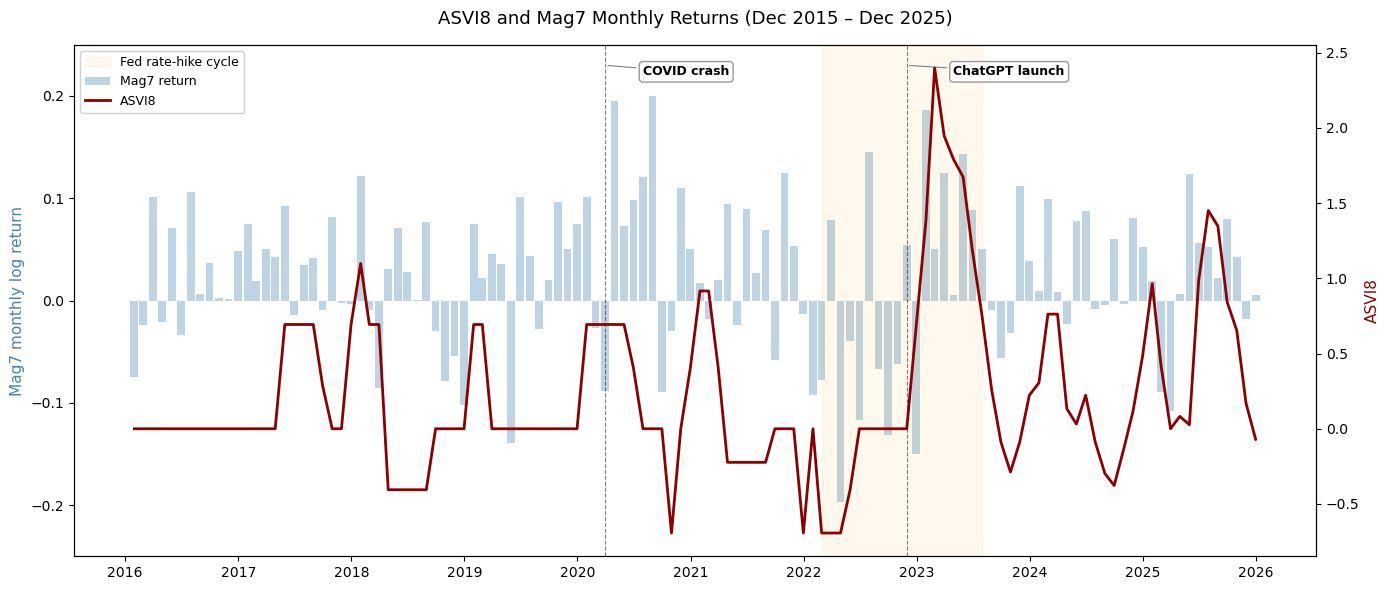

In [80]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(df["date"], df["mag7_ret"], color="steelblue", alpha=0.35, width=25, label="Mag7 return")
ax1.set_ylabel("Mag7 monthly log return", color="steelblue", fontsize=11)
ax1.set_ylim(-0.25, 0.25)

ax2 = ax1.twinx()
ax2.plot(df["date"], df["ASVI8"], color="darkred", linewidth=2, label="ASVI8")
ax2.set_ylabel("ASVI8", color="darkred", fontsize=11)

# Rate-hike shading
ax1.axvspan(pd.Timestamp("2022-03-01"), pd.Timestamp("2023-07-31"), alpha=0.07, color="orange", label="Fed rate-hike cycle")

# Event markers — labels offset to avoid line overlap
ax1.axvline(pd.Timestamp("2020-03-31"), color="black", linestyle="--", linewidth=0.8, alpha=0.5)
ax1.annotate("COVID crash", xy=(pd.Timestamp("2020-03-31"), 0.23), xytext=(pd.Timestamp("2020-07-31"), 0.23),
             fontsize=9, fontweight="bold", ha="left", va="top",
             arrowprops=dict(arrowstyle="-", color="gray", lw=0.8),
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

ax1.axvline(pd.Timestamp("2022-11-30"), color="black", linestyle="--", linewidth=0.8, alpha=0.5)
ax1.annotate("ChatGPT launch", xy=(pd.Timestamp("2022-11-30"), 0.23), xytext=(pd.Timestamp("2023-04-30"), 0.23),
             fontsize=9, fontweight="bold", ha="left", va="top",
             arrowprops=dict(arrowstyle="-", color="gray", lw=0.8),
             bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.8))

ax1.set_title("ASVI8 and Mag7 Monthly Returns (Dec 2015 – Dec 2025)", fontsize=13, pad=15)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.show()